# What is the most optimal skill to learn for Data Analysts?

### Methodology

1. Group skills to determine median salary and likelihood of being in posting
2. Visualize median salary vs percent skill demand
3. (Optional) Determine if certain technologies are more prevalent


In [9]:
# Importing Libraries
import ast
import seaborn as sns
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [10]:
df_DA_India = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()


In [11]:
df_DA_India = df_DA_India.dropna(subset=['salary_year_avg'])

df_DA_India_exploded = df_DA_India.explode('job_skills')

df_DA_India_exploded[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
11412,50400.0,python
11412,50400.0,sql
11412,50400.0,aws
11412,50400.0,azure
11412,50400.0,excel


In [23]:
df_DA_skills = df_DA_India_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)
df_DA_skills = df_DA_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'})
DA_job_count = len(df_DA_India)
df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

skill_percent = 5
df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] >= skill_percent]

df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,46,96050.00,48.936170
excel,39,98500.00,41.489362
python,36,96050.00,38.297872
tableau,20,108087.50,21.276596
r,18,79200.00,19.148936
power bi,17,111175.00,18.085106
azure,15,93600.00,15.957447
aws,12,79200.00,12.765957
oracle,11,79200.00,11.702128


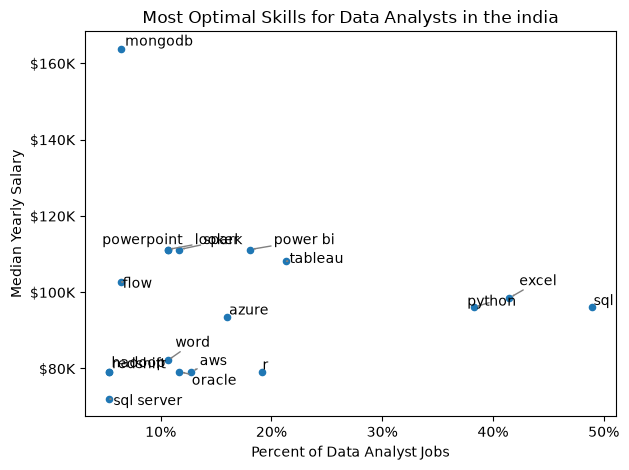

In [24]:
from adjustText import adjust_text

df_DA_skills_high_demand.plot(kind='scatter', x='skill_percent', y='median_salary')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))

# Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
plt.title('Most Optimal Skills for Data Analysts in the india')

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


<Figure size 1000x600 with 0 Axes>

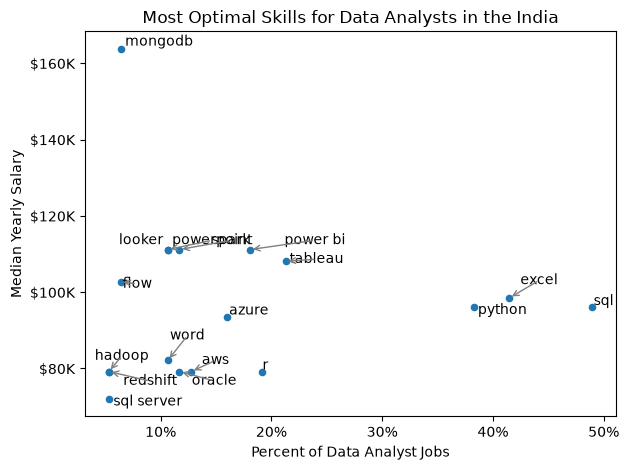

In [25]:
from matplotlib.ticker import PercentFormatter
from adjustText import adjust_text
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_DA_skills_high_demand is already defined
plt.figure(figsize=(10, 6))

df_DA_skills_high_demand.plot(
    kind='scatter', x='skill_percent', y='median_salary')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(
        df_DA_skills_high_demand['skill_percent'].iloc[i],
        df_DA_skills_high_demand['median_salary'].iloc[i],
        txt
    ))

# Adjust text to avoid overlap
adjust_text(
    texts,
    arrowprops=dict(arrowstyle='->', color='gray'),
    force_text=(0.5, 0.7),
    max_iterations=1000
)

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
plt.title('Most Optimal Skills for Data Analysts in the India')

ax = plt.gca()
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()

In [28]:
df_technology = df['job_type_skills'].copy()

# remove duplicates
df_technology = df_technology.drop_duplicates()

# remove NaN values
df_technology = df_technology.dropna()

# combine all dictionaries into one
technology_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row)  # convert string to dictionary
    for key, value in row_dict.items():
        if key in technology_dict:  # if key already exists in technology_dict, add value to existing
            technology_dict[key] += value
        else:  # if key does not exist in technology_dict, add key and value
            technology_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict


{'analyst_tools': ['ssrs',
  'powerpoint',
  'cognos',
  'sharepoint',
  'power bi',
  'esquisse',
  'powerbi',
  'sheets',
  'word',
  'spss',
  'microstrategy',
  'sap',
  'datarobot',
  'splunk',
  'spreadsheet',
  'excel',
  'dax',
  'ms access',
  'visio',
  'msaccess',
  'nuix',
  'looker',
  'ssis',
  'tableau',
  'qlik',
  'sas',
  'alteryx',
  'outlook'],
 'programming': ['go',
  'haskell',
  'mongodb',
  'perl',
  'mongo',
  'r',
  'typescript',
  'matlab',
  'vba',
  'julia',
  'ruby',
  'css',
  'lua',
  'visual basic',
  'rust',
  'assembly',
  'ocaml',
  'no-sql',
  'c',
  'delphi',
  'fortran',
  'groovy',
  'dart',
  'python',
  'objective-c',
  'c#',
  'nosql',
  'pascal',
  'erlang',
  'clojure',
  'c++',
  'bash',
  'scala',
  'lisp',
  'solidity',
  'golang',
  'kotlin',
  'shell',
  'java',
  'javascript',
  'html',
  'apl',
  'vb.net',
  'f#',
  'elixir',
  'crystal',
  'cobol',
  'php',
  'sass',
  'sas',
  'swift',
  'powershell',
  'sql',
  't-sql',
  'visualba

In [29]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,ssrs
0,analyst_tools,powerpoint
0,analyst_tools,cognos
0,analyst_tools,sharepoint
0,analyst_tools,power bi
...,...,...
9,sync,unify
9,sync,zoom
9,sync,rocketchat
9,sync,mattermost


In [32]:
df_plot=df_DA_skills_high_demand.merge(df_technology, left_on='job_skills', right_on='skills')

c:\Users\HP\anaconda3\envs\python_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


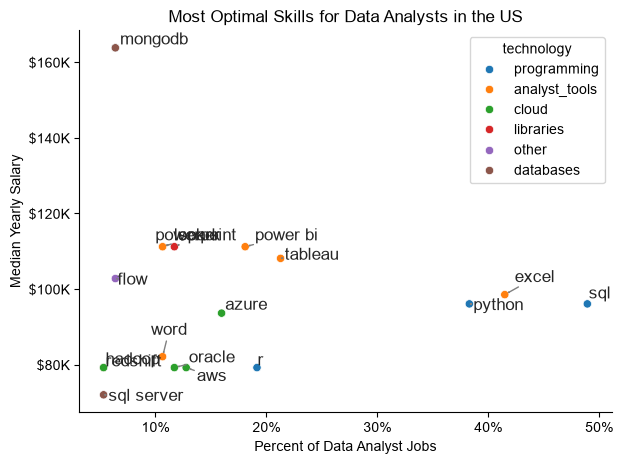

In [33]:
from adjustText import adjust_text

# df_plot.plot(kind='scatter', x='skill_percent', y='median_salary')
sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology'
)

sns.despine()
sns.set_theme(style='ticks')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))

# Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary')
plt.title('Most Optimal Skills for Data Analysts in the US')

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()

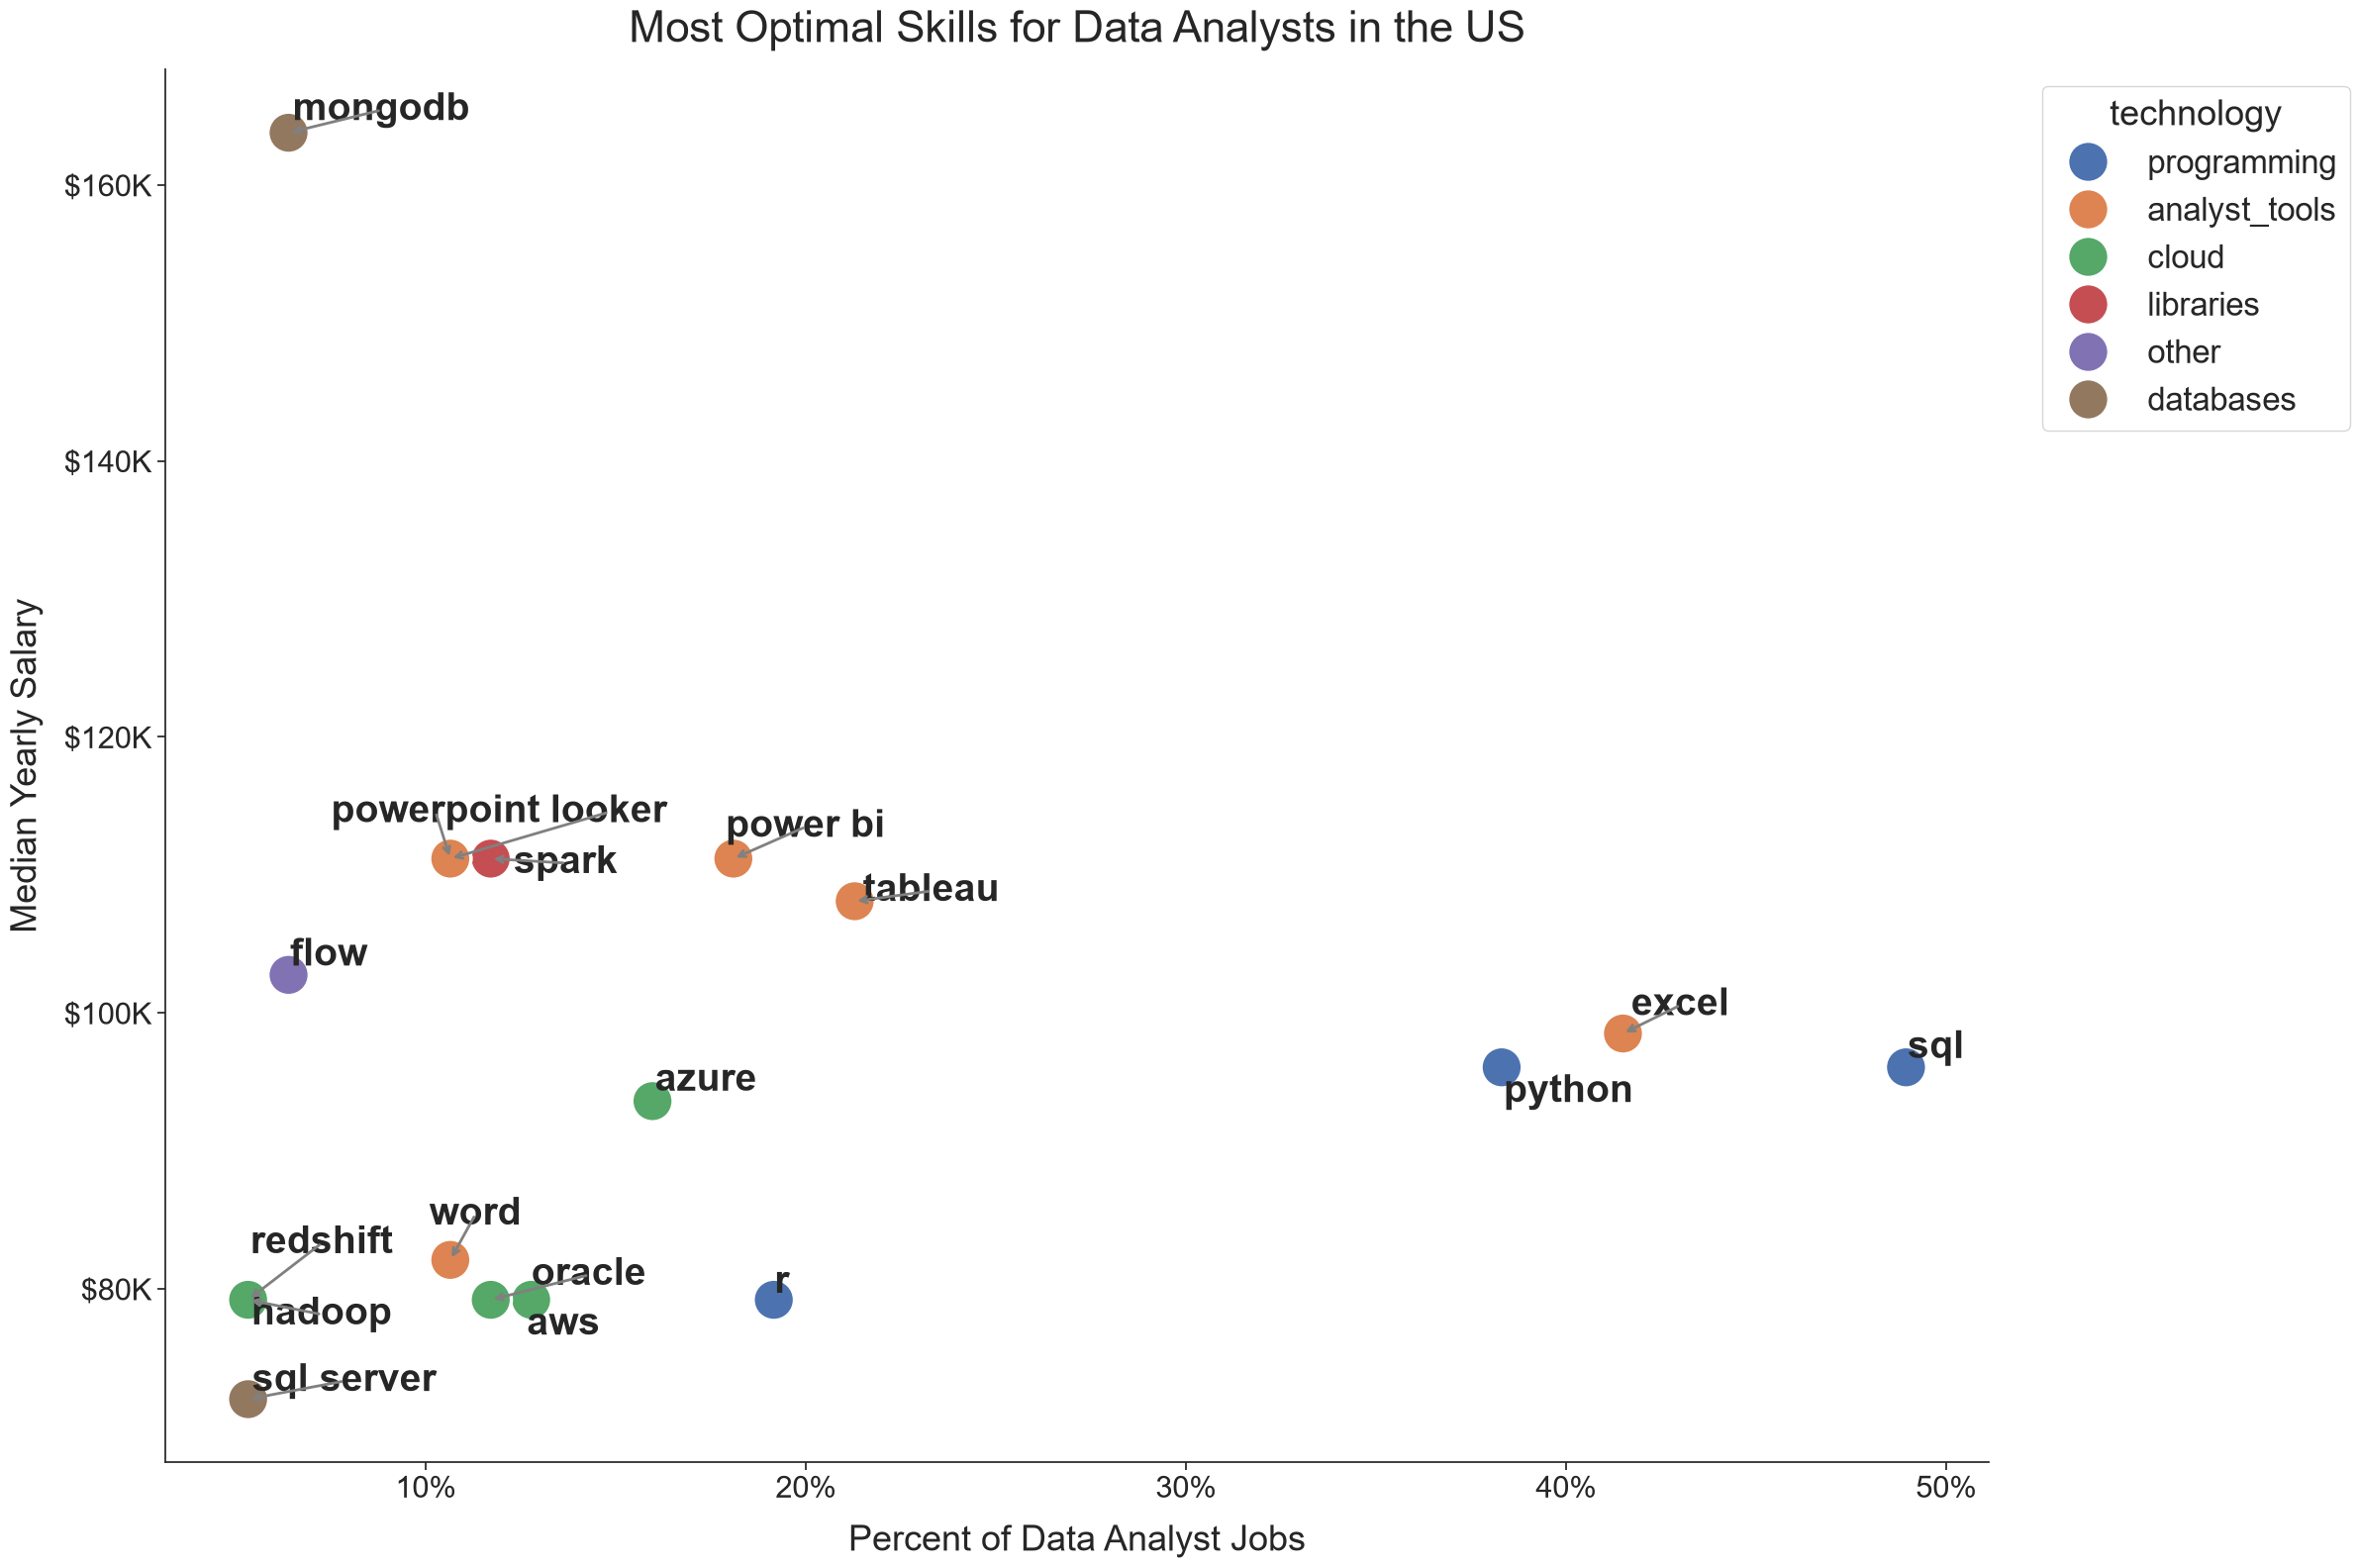

In [40]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(24, 16))

sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology',
    s=900
)

sns.despine()
sns.set_theme(style='ticks')

# Prepare texts for adjustText with a massive font size
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(
        df_DA_skills_high_demand['skill_percent'].iloc[i],
        df_DA_skills_high_demand['median_salary'].iloc[i],
        txt,
        fontsize=28,
        weight='bold'
    ))

# Adjust text with high forces to ensure labels are large, spaced out, and fully readable
adjust_text(
    texts,
    arrowprops=dict(arrowstyle='->', color='gray', lw=2),
    force_text=(2.5, 3.0),
    force_points=(2.5, 3.0),
    max_iterations=5000
)

# Set axis labels, title, and legend with huge font sizes
plt.xlabel('Percent of Data Analyst Jobs', fontsize=26, labelpad=15)
plt.ylabel('Median Yearly Salary', fontsize=26, labelpad=15)
plt.title('Most Optimal Skills for Data Analysts in the US', fontsize=32, pad=20)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=24, title='technology', title_fontsize=26)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=22)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()